In [29]:
# 1. Libraries
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, correlate
%matplotlib widget

In [30]:
# 2. List the files to compare
input_folder = Path("raw/MCP")
output_folder = Path("output/mcp_timetrace")
filenames = [
    "26-11-09_00045_TDC_TIMEHIST_BC_chopper.txt",
    #"26-11-09_00007_TDC_TIMEHIST_BC_chopper1.txt",
    #"26-11-09_00035_TDC_TIMEHIST_BC_chopper.txt",
    #"26-11-09_00036_TDC_TIMEHIST_BC_chopper.txt",
    # Add more filenames here.
]

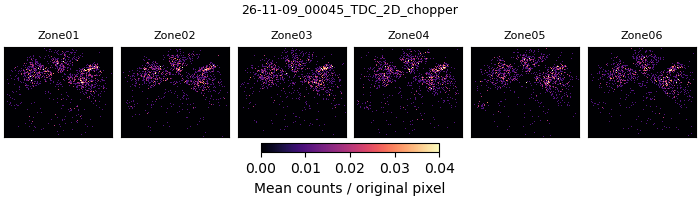

In [31]:
# 2b. Matching detector images: Zone01 -> Zone06, side by side
zone_display_bin_size = 10      # display block mean; 1 = original detector pixels
zone_upper_percentile = 99.5
zone_vmax = None                # None = common percentile scale for each row
zone_figures = []
zone_prefixes = []
for name in filenames:
    # Example: ..._TDC_TIMEHIST_BC_chopper1.txt -> ..._TDC_2D_chopper1
    scan, channel = Path(name).stem.split("_TDC_TIMEHIST_", 1)
    chopper = channel.split("_", 1)[1]  # drop BC/WD
    prefix = f"{scan}_TDC_2D_{chopper}"
    if prefix not in zone_prefixes:
        zone_prefixes.append(prefix)

output_folder.mkdir(parents=True, exist_ok=True)
for prefix in zone_prefixes:
    zone_images = []
    for zone in range(1, 7):
        path = input_folder / f"{prefix}_Zone{zone:02d}.txt"
        try:
            image = np.loadtxt(path)
            h, w = image.shape
            b = zone_display_bin_size if h % zone_display_bin_size == 0 and w % zone_display_bin_size == 0 else 1
            shown = image.reshape(h // b, b, w // b, b).mean(axis=(1, 3))
            zone_images.append(shown)
        except (OSError, ValueError) as error:
            zone_images.append(None)
            print(f"Skipping {path.name}: {error}")
    positives = [image[np.isfinite(image) & (image > 0)]
                 for image in zone_images if image is not None]
    positive = np.concatenate(positives) if positives else np.array([])
    vmax = zone_vmax if zone_vmax is not None else (
        np.percentile(positive, zone_upper_percentile) if positive.size else 1.0)
    vmax = max(float(vmax), 1e-12)
    zone_figure, axes = plt.subplots(1, 6, figsize=(7, 2), constrained_layout=True)
    artist = None
    for zone, (ax, image) in enumerate(zip(axes, zone_images), 1):
        ax.set_title(f"Zone{zone:02d}", fontsize=8)
        if image is None:
            ax.text(0.5, 0.5, "Missing", ha="center", va="center", transform=ax.transAxes, fontsize=7)
        else:
            artist = ax.imshow(image, origin="lower", cmap="magma", vmin=0, vmax=vmax,
                               interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
    zone_figure.suptitle(prefix, fontsize=9)
    if artist is not None:
        # Shared limits and colorbar apply to every zone in this row.
        zone_figure.colorbar(artist, ax=list(axes), orientation="horizontal",
                            label="Mean counts / original pixel", shrink=0.8, fraction=0.08)
    zone_figures.append(zone_figure)
    zone_figure.savefig(output_folder / f"{prefix}_zones.png", dpi=200)
    plt.show()


In [32]:
output_folder / f"{prefix}_zones.png"

PosixPath('output/mcp_timetrace/26-11-09_00045_TDC_2D_chopper_zones.png')

In [33]:
# 3. Plot and time-axis settings
peak_spacing = 105.21           # manual period if automatic estimation is disabled
auto_peak_spacing = True        # inspect and choose the period separately for each file
period_search_bins = (50, 500)  # allowed fundamental period range (acquisition bins)
refine_peak_spacing = True      # refine each file's period against detected maxima
peak_half_width = 24
first_bin = 500
last_bin = None                 # exclusive; None = end of each file
plot_start, plot_stop = 0, 45000  # view limits in BINS; None, None shows everything

# Time calibration: 37 acquisition bins per nanosecond.
bins_per_ns = 37.0
t0_ns = 0.0                     # time assigned to bin zero
show_bin_axis = True            # acquisition bins on the top axis
# Keep plot_start/plot_stop in bins; plotted limits are converted to ns.


In [34]:
# 4. Integrate EVERY equally spaced peak in EVERY file
traces = [np.loadtxt(input_folder / name).reshape(-1) for name in filenames]
number_of_bins = len(traces[0])
if any(len(trace) != number_of_bins for trace in traces):
    raise ValueError("A shared acquisition-bin axis requires equal trace lengths")
bin_width_ns = 1.0 / bins_per_ns
t1_ns = t0_ns + (number_of_bins - 1) * bin_width_ns
time_zero_ns = t0_ns
# For secondary_xaxis: bottom time -> top bin, and its inverse.
bin_axis_functions = (lambda time: (time - t0_ns) / bin_width_ns,
                      lambda bins: t0_ns + bins * bin_width_ns)
print(f"{number_of_bins} bins: {t0_ns:g}–{t1_ns:g} ns; {bin_width_ns:g} ns/bin")
# Estimate each trace's bunch period independently using its autocorrelation.
peak_alignment = []
for name, trace in zip(filenames, traces):
    stop = len(trace) if last_bin is None else min(last_bin, len(trace))
    segment = trace[first_bin:stop]
    anchor = first_bin + int(np.argmax(segment))
    signal = segment - segment.mean()
    correlation = correlate(signal, signal, mode="full", method="fft")[len(signal)-1:]
    correlation = correlation / correlation[0] if correlation[0] > 0 else np.zeros_like(correlation)
    low, high = period_search_bins
    high = min(high, len(segment) // 4)
    candidates, _ = find_peaks(correlation[low:high+1])
    candidates = candidates + low
    spacing = float(peak_spacing)
    if auto_peak_spacing:
        if not len(candidates) or correlation[candidates].max() <= 0:
            raise ValueError(f"{name}: no periodic signal found; adjust period_search_bins or set auto_peak_spacing=False")
        # The first strong recurrence avoids selecting twice/three times the period.
        strong = candidates[correlation[candidates] >= 0.85 * correlation[candidates].max()]
        coarse_period = float(strong[0])
        # Several recurrence peaks give sub-bin precision before assigning pulse order.
        recurrence_orders, recurrence_lags = [], []
        for order in range(1, 11):
            expected = order * coarse_period
            start = max(1, int(expected - 0.15 * coarse_period))
            end = min(len(correlation)-2, int(expected + 0.15 * coarse_period))
            if end <= start:
                break
            lag = start + int(np.argmax(correlation[start:end+1]))
            if correlation[lag] <= 0:
                continue
            curvature = correlation[lag-1] - 2*correlation[lag] + correlation[lag+1]
            shift = 0.5*(correlation[lag-1]-correlation[lag+1])/curvature if curvature else 0.0
            recurrence_orders.append(order)
            recurrence_lags.append(lag + np.clip(shift, -0.5, 0.5))
        spacing = float(np.dot(recurrence_orders, recurrence_lags) / np.dot(recurrence_orders, recurrence_orders))
    estimated_period = spacing
    detected, _ = find_peaks(segment, distance=max(1, int(0.7 * spacing)),
                             prominence=max(1.0, 0.1 * np.max(segment)))
    detected = detected + first_bin
    orders = np.rint((detected - anchor) / spacing).astype(int)
    keep = np.abs(detected - (anchor + orders * spacing)) < 0.25 * spacing
    detected, orders = detected[keep], orders[keep]
    fitted_anchor = float(anchor)
    for _ in range(3):
        if refine_peak_spacing and len(detected) >= 3:
            spacing, fitted_anchor = np.polyfit(orders, detected, 1)
        elif len(detected):
            fitted_anchor = float(np.median(detected - spacing * orders))
        residual = detected - (fitted_anchor + spacing * orders)
        keep = np.abs(residual) <= max(3.0, 0.07 * spacing)
        if keep.sum() < 3 or keep.all():
            break
        detected, orders = detected[keep], orders[keep]
    peak_alignment.append(dict(filename=name, strongest_bin=anchor,
                               fitted_anchor=float(fitted_anchor), spacing=float(spacing),
                               estimated_period=estimated_period, detected_peaks=detected,
                               correlation=correlation[:min(len(correlation), 3*high+1)]))
    print(f"{name}: estimated {estimated_period:.6f} bins; fitted {spacing:.6f} bins = {spacing / bins_per_ns:.6f} ns")

results = []
peak_windows = []
for name, trace, alignment in zip(filenames, traces, peak_alignment):
    stop = len(trace) if last_bin is None else min(last_bin, len(trace))
    anchor = alignment["strongest_bin"]
    spacing = alignment["spacing"]
    fitted_anchor = alignment["fitted_anchor"]
    if not (0 < peak_half_width < spacing / 2):
        raise ValueError("Peak half-width must be positive and smaller than half the spacing")
    first_order = int(np.ceil((first_bin + peak_half_width - fitted_anchor) / spacing))
    last_order = int(np.floor((stop - 1 - peak_half_width - fitted_anchor) / spacing))
    bins = fitted_anchor + np.arange(first_order, last_order + 1) * spacing
    left = np.ceil(bins - peak_half_width).astype(int)
    right = np.floor(bins + peak_half_width).astype(int) + 1
    cumulative = np.r_[0., np.cumsum(trace, dtype=float)]
    counts = cumulative[right] - cumulative[left]
    x = time_zero_ns + bins * bin_width_ns
    results.append((bins, x, counts))
    peak_windows.append((left, right))
    print(name, f": {len(counts)} windows; strongest bin {anchor}; fitted spacing {spacing:.6f} bins")
for name, trace, (_, _, counts) in zip(filenames, traces, results):
    stop = len(trace) if last_bin is None else min(last_bin, len(trace))
    print(f"{name}: {counts.sum():g} counts in peaks / {trace[first_bin:stop].sum():g} counts in analysis range")

80001 bins: 0–2162.16 ns; 0.027027 ns/bin
26-11-09_00045_TDC_TIMEHIST_BC_chopper.txt: estimated 105.043142 bins; fitted 105.041571 bins = 2.838961 ns
26-11-09_00045_TDC_TIMEHIST_BC_chopper.txt : 757 windows; strongest bin 947; fitted spacing 105.041571 bins
26-11-09_00045_TDC_TIMEHIST_BC_chopper.txt: 1.85148e+06 counts in peaks / 2.08529e+06 counts in analysis range


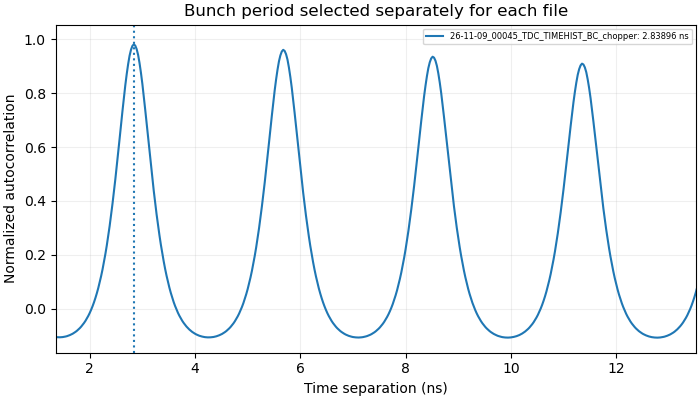

In [35]:
# 4a. Check each automatically selected bunch period
period_figure, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
for alignment in peak_alignment:
    correlation = alignment["correlation"]
    line, = ax.plot(np.arange(len(correlation)) / bins_per_ns, correlation,
                    label=f"{Path(alignment['filename']).stem}: {alignment['spacing']/bins_per_ns:.5f} ns")
    ax.axvline(alignment["spacing"] / bins_per_ns, color=line.get_color(), linestyle=":")
ax.set(xlabel="Time separation (ns)", ylabel="Normalized autocorrelation",
       xlim=(period_search_bins[0]/bins_per_ns, period_search_bins[1]/bins_per_ns),
       title="Bunch period selected separately for each file")
ax.legend(fontsize=6)
ax.grid(alpha=0.2)
plt.show()

In [36]:
# 4b. Time -> bin converter and nearest integrated peak
requested_time_ns = 86.35       # edit this time, then rerun this cell
selected_file_index = 0         # position in filenames; determines available peak windows

requested_bin = (requested_time_ns - t0_ns) / bin_width_ns
nearest_bin = int(np.rint(requested_bin))
print(f"Requested time: {requested_time_ns:.6f} ns")
print(f"Fractional bin: {requested_bin:.6f}; nearest acquisition bin: {nearest_bin}")
print(f"Nearest bin time: {t0_ns + nearest_bin * bin_width_ns:.6f} ns")

centers, times, counts = results[selected_file_index]
starts, stops = peak_windows[selected_file_index]
peak_index = int(np.argmin(np.abs(times - requested_time_ns)))
peak_center_bin = float(centers[peak_index])
peak_center_time_ns = float(times[peak_index])
start_bin = int(starts[peak_index])
stop_bin = int(stops[peak_index])  # exclusive: exactly the slice used for integration
selected_bin_range = (start_bin, stop_bin)
selected_time_range_ns = (t0_ns + start_bin * bin_width_ns,
                          t0_ns + (stop_bin - 1) * bin_width_ns)
# Pixel/bin boundaries used by the shaded windows in the diagnostics:
selected_window_edges_ns = (t0_ns + (start_bin - 0.5) * bin_width_ns,
                            t0_ns + (stop_bin - 0.5) * bin_width_ns)
print(f"\nFile: {filenames[selected_file_index]}")
print(f"Nearest integrated peak: {peak_center_time_ns:.6f} ns (center bin {peak_center_bin:.6f})")
print(f"Selected file bunch period: {peak_alignment[selected_file_index]['spacing']:.6f} bins ({peak_alignment[selected_file_index]['spacing'] / bins_per_ns:.6f} ns)")
print(f"Integration half-width: {peak_half_width:g} bins")
print(f"Bin range: {start_bin}–{stop_bin - 1} inclusive; Python slice [{start_bin}:{stop_bin}]")
print(f"Sample-time range: {selected_time_range_ns[0]:.6f}–{selected_time_range_ns[1]:.6f} ns")
print(f"Shaded window edges: {selected_window_edges_ns[0]:.6f}–{selected_window_edges_ns[1]:.6f} ns")
print(f"Integrated counts: {counts[peak_index]:g}")
if requested_time_ns < times[0] or requested_time_ns > times[-1]:
    print("Requested time is outside the available peak-center range; selected the nearest endpoint peak.")


Requested time: 86.350000 ns
Fractional bin: 3194.950000; nearest acquisition bin: 3195
Nearest bin time: 86.351351 ns

File: 26-11-09_00045_TDC_TIMEHIST_BC_chopper.txt
Nearest integrated peak: 85.277989 ns (center bin 3155.285583)
Selected file bunch period: 105.041571 bins (2.838961 ns)
Integration half-width: 24 bins
Bin range: 3132–3179 inclusive; Python slice [3132:3180]
Sample-time range: 84.648649–85.918919 ns
Shaded window edges: 84.635135–85.932432 ns
Integrated counts: 4471


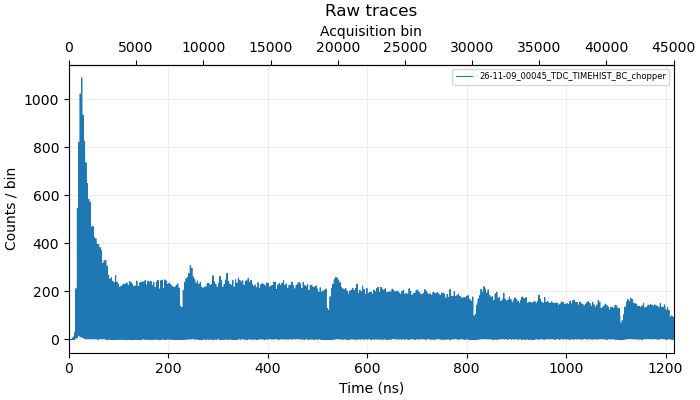

In [37]:
# 5. Raw time traces before the integrated-peak plots
xlabel = "Time (ns)"
view_start = None if plot_start is None else time_zero_ns + plot_start * bin_width_ns
view_stop = None if plot_stop is None else time_zero_ns + plot_stop * bin_width_ns

raw_figure, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
for name, trace in zip(filenames, traces):
    bins = np.arange(len(trace))
    x = time_zero_ns + bins * bin_width_ns
    ax.plot(x, trace, linewidth=0.8, label=Path(name).stem)
ax.set(xlabel=xlabel, ylabel="Counts / bin", title="Raw traces", xlim=(view_start, view_stop))
ax.legend(fontsize=6)
if show_bin_axis:
    ax.secondary_xaxis("top", functions=bin_axis_functions).set_xlabel("Acquisition bin")
ax.grid(alpha=0.2)
plt.show()

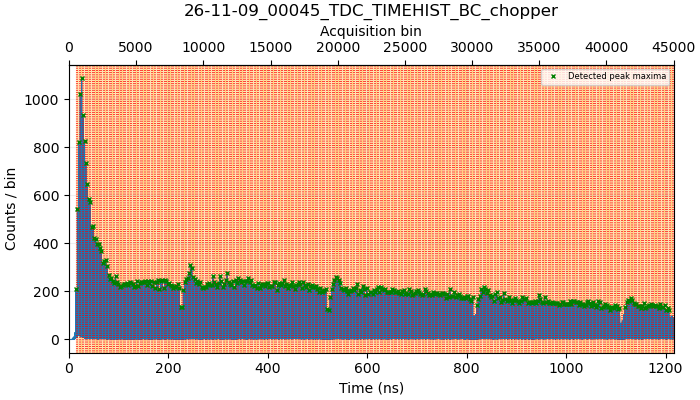

In [38]:
# 6. Peak-window diagnostics, one compact figure per file
# Orange: integrated bins; red dotted lines: fitted peak centers.
diagnostic_figures = []
for name, trace, (centers, _, counts), (left, right), alignment in zip(filenames, traces, results, peak_windows, peak_alignment):
    diagnostic_figure, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
    bins = np.arange(len(trace))
    x = time_zero_ns + bins * bin_width_ns
    ax.plot(x, trace, linewidth=0.8)
    for center, start, end in zip(centers, left, right):
        if (plot_start is None or center >= plot_start) and (plot_stop is None or center <= plot_stop):
            low, high = start - 0.5, end - 0.5
            position = center
            low, high = time_zero_ns + np.array([low, high]) * bin_width_ns
            position = time_zero_ns + center * bin_width_ns
            ax.axvspan(low, high, color="orange", alpha=0.2)
            ax.axvline(position, color="red", linestyle=":", linewidth=0.6)
    ax.set(xlabel=xlabel, ylabel="Counts / bin", title=Path(name).stem,
           xlim=(view_start, view_stop))
    if show_bin_axis:
        ax.secondary_xaxis("top", functions=bin_axis_functions).set_xlabel("Acquisition bin")
    detected = np.asarray(alignment["detected_peaks"], dtype=int)
    detected_times = time_zero_ns + detected * bin_width_ns
    ax.plot(detected_times, trace[detected], "x", color="green", markersize=3,
            label="Detected peak maxima")
    ax.legend(fontsize=6)
    ax.grid(alpha=0.2)
    diagnostic_figures.append(diagnostic_figure)
    plt.show()

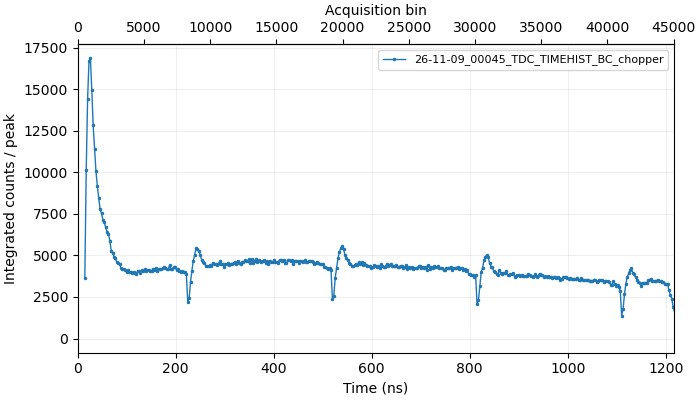

In [39]:
# 7. Integrated peak counts: one line per file
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
for name, (bins, x, counts) in zip(filenames, results):
    ax.plot(x, counts, ".-", markersize=3, linewidth=1, label=Path(name).stem)
ax.set(xlabel=xlabel, ylabel="Integrated counts / peak")
ax.set_xlim(view_start, view_stop)
ax.legend(fontsize=8)
if show_bin_axis:
    ax.secondary_xaxis("top", functions=bin_axis_functions).set_xlabel("Acquisition bin")
ax.grid(alpha=0.2)
plt.show()

In [40]:
results[0][0].shape

(757,)

In [ ]:
# Ratio of the first two files, compared at the SAME time points.
# Different periods give different peak counts; interpolate the second line.
if len(results) < 2:
    print("Select at least two time traces to plot their ratio.")
else:
    ratio_figure, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
    ratio_times = results[0][1]
    reference_counts = np.interp(ratio_times, results[1][1], results[1][2], left=np.nan, right=np.nan)
    ratio_counts = np.full(len(ratio_times), np.nan)
    np.divide(results[0][2], reference_counts, out=ratio_counts, where=reference_counts > 0)
    ax.plot(ratio_times, ratio_counts, ".-", markersize=3, linewidth=1)
    ax.grid(alpha=0.2)
    ax.set(xlabel=xlabel, ylabel="Ratio (second trace interpolated in time)")
    plt.show()

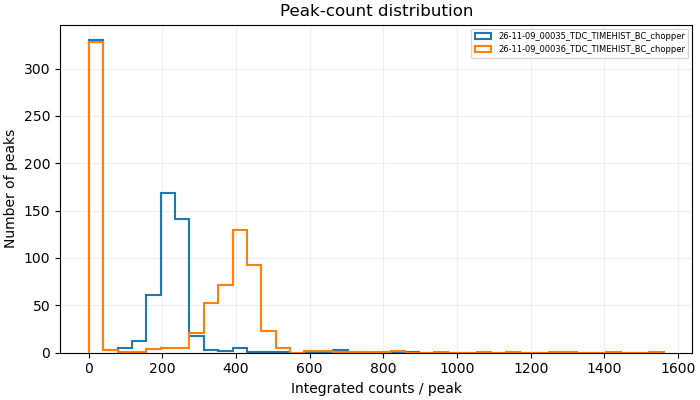

In [ ]:
# 8. Distribution of integrated peak counts
histogram_bins = 40
histogram_figure, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
all_counts = np.concatenate([counts for _, _, counts in results])
count_edges = np.histogram_bin_edges(all_counts, bins=histogram_bins)
for name, (_, _, counts) in zip(filenames, results):
    ax.hist(counts, bins=count_edges, histtype="step", linewidth=1.5, label=Path(name).stem)
ax.set(xlabel="Integrated counts / peak", ylabel="Number of peaks", title="Peak-count distribution")
ax.legend(fontsize=6)
ax.grid(alpha=0.2)
plt.show()

In [ ]:
# 9. Save plots, diagnostics, and peak-count data
output_folder.mkdir(parents=True, exist_ok=True)
mode = "integrated_peaks"
np.savetxt(output_folder / "peak_alignment.csv",
           np.array([[i, a["strongest_bin"], a["fitted_anchor"], a["spacing"], a["spacing"] / bins_per_ns]
                     for i, a in enumerate(peak_alignment)]), delimiter=",", comments="",
           header="file_list_index,strongest_bin,fitted_anchor_bin,fitted_spacing_bins,bunch_period_ns")
period_figure.savefig(output_folder / "bunch_period_diagnostic.png", dpi=160)
axis_name = "time_ns"
fig.savefig(output_folder / f"comparison_{mode}_{axis_name}.png", dpi=160)
raw_figure.savefig(output_folder / f"comparison_raw_traces_{axis_name}.png", dpi=160)
histogram_figure.savefig(output_folder / "peak_count_distribution.png", dpi=160)
for name, diagnostic_figure in zip(filenames, diagnostic_figures):
    diagnostic_figure.savefig(output_folder / f"{Path(name).stem}_peak_windows_{axis_name}.png", dpi=160)
for name, (bins, x, counts) in zip(filenames, results):
    np.savetxt(output_folder / f"{Path(name).stem}_{mode}_{axis_name}.csv",
               np.c_[bins, x, counts], delimiter=",",
               header=f"bin_index,{axis_name},counts", comments="")
print("Saved in", output_folder.resolve())

Saved in /Users/riccardo/Github/SEXTANTS_261105/output/mcp_timetrace
